Sixty apartments in Austin, Texas: their monthly rent, their size, and a few other features. The
questions are the ones a renter would ask. What does a typical apartment cost? How much more does
each extra square foot cost? And how far can the answers be trusted?

The data are from Dr. Sager's course datasets at the University of Texas at Austin. To run this
yourself, put the two data files from this page beside the notebook.

You also need `pip install numpy pandas matplotlib scipy statsmodels`. For the longer version of
this material in Python, see the free book
[An Introduction to Statistical Learning, with Applications in Python](https://www.statlearning.com/).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import linear_reset, het_breuschpagan

## The data

Two files with the same 60 apartments. The first has only `Rent` (dollars per month) and `Area`
(square feet); the second adds seven more columns. `Security`, `Parking` and `Shuttle` are yes/no
flags (1 = yes). The original page gives no units for `Distance` or `Age`. The cell checks that
the two files agree on the columns they share.

In [2]:
rents1 = pd.read_csv("AustinApartmentRents1.txt", sep=r"\s+")
df = pd.read_csv("AustinApartmentRents2.txt", sep=r"\s+")
print(rents1.shape, df.shape, "| same Rent and Area in both:", rents1.equals(df[["Rent", "Area"]]))
df.head()

(60, 2) (60, 9) | same Rent and Area in both: True


,Rent,Area,Bedrooms,Bathrooms,Security,Parking,Distance,Shuttle,Age
0,519,725,1,1,0,0,10.5,1,9
1,765,995,2,2,0,0,6.5,1,17
2,475,481,1,1,0,0,6.5,1,17
3,575,925,2,2,0,1,4.0,1,9
4,415,600,1,1,0,0,5.0,1,30


## Exploring the data

One row per column: its centre, its spread, its range, and its correlation with rent. Before you
run it, guess which column moves most closely with rent.

In [3]:
summary = df.describe().T[["mean", "std", "min", "50%", "max"]]
summary["corr with Rent"] = df.corr()["Rent"]
summary.round(2)

,mean,std,min,50%,max,corr with Rent
Rent,572.27,140.52,399.0,535.0,1050.0,1.00
Area,816.05,243.24,474.0,755.0,1864.0,0.87
Bedrooms,1.52,0.72,1.0,1.0,5.0,0.75
Bathrooms,1.25,0.44,1.0,1.0,2.0,0.77
Security,0.17,0.38,0.0,0.0,1.0,0.01
Parking,0.13,0.34,0.0,0.0,1.0,0.17
Distance,5.94,1.70,1.1,6.0,10.5,-0.09
Shuttle,0.87,0.34,0.0,1.0,1.0,0.11
Age,16.33,7.92,1.0,16.5,32.0,-0.05


## A confidence interval for the mean rent

The sample mean $\bar x$ estimates the mean rent of all apartments like these. A 95% confidence
interval puts a margin around it that depends on the spread $s$ and the sample size $n$:

$$\bar x \pm t_{0.025,\,n-1}\,\frac{s}{\sqrt{n}}$$

**Predict:** with the mean and standard deviation in the table, roughly how wide is the interval?

In [4]:
n = len(df)
xbar, s = df.Rent.mean(), df.Rent.std()
low, high = stats.t.interval(0.95, n - 1, loc=xbar, scale=s / np.sqrt(n))
print(f"n = {n}, mean = {xbar:.2f}, s = {s:.2f} (dollars per month)")
print(f"95% CI for the mean rent: {low:.2f} to {high:.2f}")

n = 60, mean = 572.27, s = 140.52 (dollars per month)
95% CI for the mean rent: 535.97 to 608.57


## A t test

Suppose someone claims the mean rent is \$550. The one-sample $t$ test asks how far the sample mean
sits from 550, measured in standard errors. **Predict** from the interval above, before you run it:
will the p-value be above or below 0.05?

In [5]:
test = stats.ttest_1samp(df.Rent, popmean=550)
print(f"t = {test.statistic:.3f}, p-value = {test.pvalue:.4f}")

t = 1.227, p-value = 0.2246


## A regression line

Fit $\text{Rent} = \beta_0 + \beta_1\,\text{Area} + \varepsilon$ by least squares. The formula
`Rent ~ Area` reads the same way. **Predict:** how many dollars a month does one more square foot
add?

In [6]:
simple = smf.ols("Rent ~ Area", data=df).fit()
ci = simple.conf_int()
print(f"R^2 = {simple.rsquared:.3f}")
pd.DataFrame({"coef": simple.params, "95% low": ci[0], "95% high": ci[1],
              "p-value": simple.pvalues.map("{:.2g}".format)}).round(3)

R^2 = 0.764


,coef,95% low,95% high,p-value
Intercept,160.187,97.412,222.963,3.8e-06
Area,0.505,0.431,0.579,7.8e-20


### Confidence and prediction intervals

The line gives two kinds of interval at any area. A **confidence interval** is for the *mean* rent
of all apartments of that size. A **prediction interval** is for the rent of *one* apartment of
that size. Here they are for 500 and 1,000 square feet. **Predict:** which is wider, and by about
how much?

In [7]:
new = pd.DataFrame({"Area": [500, 1000]})
bands = simple.get_prediction(new).summary_frame(alpha=0.05)
bands.index = new.Area
bands[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]].round(1)

,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
Area,,,,,
500,412.7,383.3,442.0,271.8,553.6
1000,665.2,642.8,687.5,525.5,804.8


The same two intervals at every area, drawn around the line. The shaded band is the confidence
interval; the dashed lines are the prediction interval.

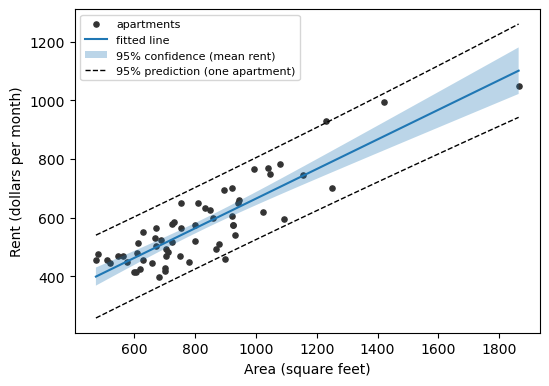

In [8]:
grid = pd.DataFrame({"Area": np.linspace(df.Area.min(), df.Area.max(), 100)})
g = simple.get_prediction(grid).summary_frame(alpha=0.05)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(df.Area, df.Rent, s=14, color="0.2", label="apartments")
ax.plot(grid.Area, g["mean"], label="fitted line")
ax.fill_between(grid.Area, g.mean_ci_lower, g.mean_ci_upper, alpha=0.3, label="95% confidence (mean rent)")
ax.plot(grid.Area, g.obs_ci_lower, "k--", linewidth=1, label="95% prediction (one apartment)")
ax.plot(grid.Area, g.obs_ci_upper, "k--", linewidth=1)
ax.set(xlabel="Area (square feet)", ylabel="Rent (dollars per month)")
ax.legend(fontsize=8, loc="upper left")
plt.show()
# alt: Rent rises with area along the fitted line, from about 400 dollars at 474 square feet to about 1,100 dollars at 1,864; the shaded confidence band is about 22 dollars either side of the line at 1,000 square feet and widens to about 80 at the largest apartment, while the dashed prediction lines sit about 140 to 160 dollars either side.

## Multiple linear regression

Add the number of bathrooms: $\text{Rent} = \beta_0 + \beta_1\,\text{Area} + \beta_2\,\text{Bathrooms}
+ \varepsilon$. **Predict:** once bathrooms are in the model, does the coefficient on `Area` go up,
go down, or stay where it was?

In [9]:
fit2 = smf.ols("Rent ~ Area + Bathrooms", data=df).fit()
ci = fit2.conf_int()
print(f"R^2 = {fit2.rsquared:.3f}")
pd.DataFrame({"coef": fit2.params, "95% low": ci[0], "95% high": ci[1],
              "p-value": fit2.pvalues.map("{:.2g}".format)}).round(3)

R^2 = 0.801


,coef,95% low,95% high,p-value
Intercept,143.669,84.570,202.769,9.3e-06
Area,0.387,0.288,0.487,1.6e-10
Bathrooms,89.929,34.359,145.499,0.002


Now five predictors: area, bathrooms, security, parking and distance. **Predict:** which of the
five will have a p-value below 0.05?

In [10]:
fit5 = smf.ols("Rent ~ Area + Bathrooms + Security + Parking + Distance", data=df).fit()
ci = fit5.conf_int()
print(f"R^2 = {fit5.rsquared:.3f}, adjusted R^2 = {fit5.rsquared_adj:.3f}")
pd.DataFrame({"coef": fit5.params, "95% low": ci[0], "95% high": ci[1],
              "p-value": fit5.pvalues.map("{:.2g}".format)}).round(3)

R^2 = 0.810, adjusted R^2 = 0.792


,coef,95% low,95% high,p-value
Intercept,167.450,80.993,253.908,0.00028
Area,0.396,0.295,0.498,2.1e-10
Bathrooms,92.600,36.428,148.773,0.0017
Security,-0.679,-45.645,44.287,0.98
Parking,-38.265,-90.184,13.654,0.15
Distance,-4.929,-15.054,5.196,0.33


## Multicollinearity

Multicollinearity means one predictor is (nearly) a combination of others, so the data cannot tell
their effects apart. It is easiest to see on made-up data where you know the answer. Here $y$,
$x_1$ and $x_2$ are independent random numbers between 0 and 100, and $z_2$ is $x_1 + x_2$ plus a
tiny bit of noise. Python and R draw different random numbers, even from the same seed, so the
numbers in the two versions from here to the next section will not match.

In [11]:
rng = np.random.default_rng(1234)
sim = pd.DataFrame({"y": rng.uniform(0, 100, 50), "x1": rng.uniform(0, 100, 50),
                    "x2": rng.uniform(0, 100, 50)})
sim["z2"] = sim.x1 + sim.x2 + 0.005 * rng.uniform(0, 100, 50)
sim.corr().round(3)

,y,x1,x2,z2
y,1.000,-0.299,0.040,-0.164
x1,-0.299,1.000,0.267,0.797
x2,0.040,0.267,1.000,0.795
z2,-0.164,0.797,0.795,1.000


The **variance inflation factor** of predictor $j$ is $\text{VIF}_j = 1/(1 - R_j^2)$, where $R_j^2$
comes from regressing predictor $j$ on all the other predictors. A VIF of 1 means no overlap; a
common rule of thumb calls anything above 5 or 10 a problem. The loop fits three models: all of
$x_1, x_2, z_2$; then without $z_2$; then without $x_2$. It prints each model's VIFs and the
standard error of the coefficient on $x_1$. **Predict:** how large will the VIFs be in the first
model?

In [12]:
for formula in ["y ~ x1 + x2 + z2", "y ~ x1 + x2", "y ~ x1 + z2"]:
    fit = smf.ols(formula, data=sim).fit()
    X = fit.model.exog
    vifs = [f"{variance_inflation_factor(X, j):,.1f}" for j in range(1, X.shape[1])]
    print(f"{formula:17s} R^2 = {fit.rsquared:.3f}  SE of x1 = {fit.bse['x1']:7.3f}  VIFs = {', '.join(vifs)}")

y ~ x1 + x2 + z2  R^2 = 0.129  SE of x1 =  27.453  VIFs = 36,900.7, 36,518.3, 92,984.5
y ~ x1 + x2       R^2 = 0.105  SE of x1 =   0.149  VIFs = 1.1, 1.1
y ~ x1 + z2       R^2 = 0.105  SE of x1 =   0.237  VIFs = 2.7, 2.7


## Checking the assumptions

The intervals and p-values above rest on assumptions about the errors $\varepsilon$: they are
roughly normal, the relationship is linear, and their spread is the same everywhere. The residuals
(actual minus fitted rent) stand in for the errors. The checks below use the two-predictor model,
`Rent ~ Area + Bathrooms`.

### Normality of the residuals

A normal Q-Q plot puts each residual against where it would fall if the residuals were exactly
normal. Normal residuals lie near the straight line. **Predict:** where on the plot would a few
unusually expensive apartments show up?

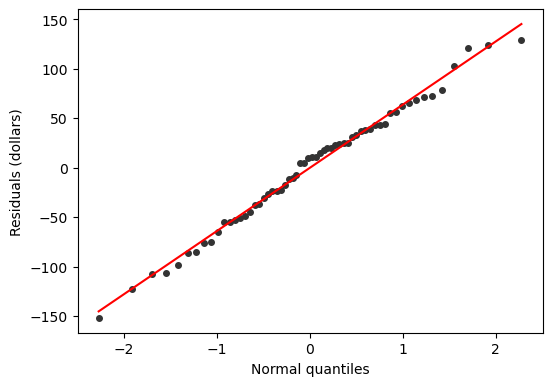

In [13]:
fig, ax = plt.subplots(figsize=(6, 4.2))
stats.probplot(fit2.resid, dist="norm", plot=ax)
ax.get_lines()[0].set(marker="o", markersize=4, color="0.2")
ax.set(title="", xlabel="Normal quantiles", ylabel="Residuals (dollars)")
plt.show()
# alt: The 60 residuals, from about -152 to +129 dollars, lie close to the straight reference line across the whole range, with the few points at each end only slightly off it.

The Shapiro-Wilk test puts a number on the same question. Its null hypothesis is that the residuals
come from a normal distribution, so a small p-value is evidence against normality.

In [14]:
sw = stats.shapiro(fit2.resid)
print(f"Shapiro-Wilk W = {sw.statistic:.3f}, p-value = {sw.pvalue:.4f}")

Shapiro-Wilk W = 0.989, p-value = 0.8460


### Linearity and constant spread

Plot the residuals against the fitted rents. If the model is right, they form a band of even width
around zero with no curve. **Predict** what a curve in this plot would mean, and what a funnel
(narrow at one end, wide at the other) would mean.

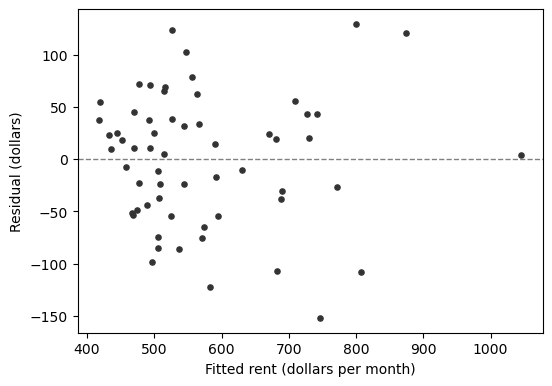

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(fit2.fittedvalues, fit2.resid, s=14, color="0.2")
ax.axhline(0, color="0.5", linestyle="--", linewidth=1)
ax.set(xlabel="Fitted rent (dollars per month)", ylabel="Residual (dollars)")
plt.show()
# alt: Residuals scatter around zero between about -152 and +129 dollars with no curve; most fitted rents fall between about 420 and 600 dollars, fewer between 600 and 880, and one apartment sits alone at a fitted rent near 1,050 dollars with a residual near zero.

Ramsey's RESET test asks whether adding the squared and cubed fitted values improves the fit. Its
null hypothesis is that they do not, that is, the linear form is enough.

In [16]:
reset = linear_reset(fit2, power=3, test_type="fitted", use_f=True)
print(f"RESET F = {reset.statistic:.3f}, p-value = {reset.pvalue:.4f}")

RESET F = 1.136, p-value = 0.3285


### Heteroscedasticity

Heteroscedasticity means the spread of the errors changes with the predictors. The Breusch-Pagan
test regresses the squared residuals on the predictors; its null hypothesis is constant spread.
The version here is Koenker's "studentized" one, the default in both Python and R, which does not
lean on the errors being normal. **Predict** from the residual plot: will it reject?

In [17]:
lm_stat, lm_p, f_stat, f_p = het_breuschpagan(fit2.resid, fit2.model.exog, robust=True)
print(f"Breusch-Pagan LM = {lm_stat:.3f}, p-value = {lm_p:.4f}")

Breusch-Pagan LM = 5.362, p-value = 0.0685


## Questions

- The \$550 claim and the 95% confidence interval gave the same verdict. Will they always? What
  would change if the interval were 99%?
- In the five-predictor model, `Parking` has a negative coefficient. Does parking lower rent, or
  could something else about those apartments explain the sign?
- The three made-up models had similar $R^2$. What, then, went wrong in the first one, and why does
  dropping either $z_2$ or $x_2$ fix it?